In [1]:

# SVM and KNN: When to Use What
# Task 1: Load and inspect the Breast Cancer dataset

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Load dataset
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name="target")

print("Dataset shape:", X.shape)
print("\nClass distribution:")
print(y.value_counts())
print("\nFirst five rows:")
print(X.head())


Dataset shape: (569, 30)

Class distribution:
target
1    357
0    212
Name: count, dtype: int64

First five rows:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10

In [3]:

# Task 2: Split data and train both models
# Scaling is important for SVM and KNN.
# Pipelines ensure scaling is fitted only on training data.

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# SVM model
svm_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", SVC(kernel="rbf"))
])

# KNN model
knn_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", KNeighborsClassifier(n_neighbors=5))
])

# Train the models
svm_model.fit(X_train, y_train)
knn_model.fit(X_train, y_train)

# Make predictions
svm_pred = svm_model.predict(X_test)
knn_pred = knn_model.predict(X_test)

# Compare accuracy
svm_accuracy = accuracy_score(y_test, svm_pred)
knn_accuracy = accuracy_score(y_test, knn_pred)

print("SVM Accuracy:", round(svm_accuracy, 4))
print("KNN Accuracy:", round(knn_accuracy, 4))

print("\nSVM Classification Report:")
print(classification_report(y_test, svm_pred,
                            target_names=data.target_names))

print("\nKNN Classification Report:")
print(classification_report(y_test, knn_pred,
                            target_names=data.target_names))


SVM Accuracy: 0.9825
KNN Accuracy: 0.9561

SVM Classification Report:
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114


KNN Classification Report:
              precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



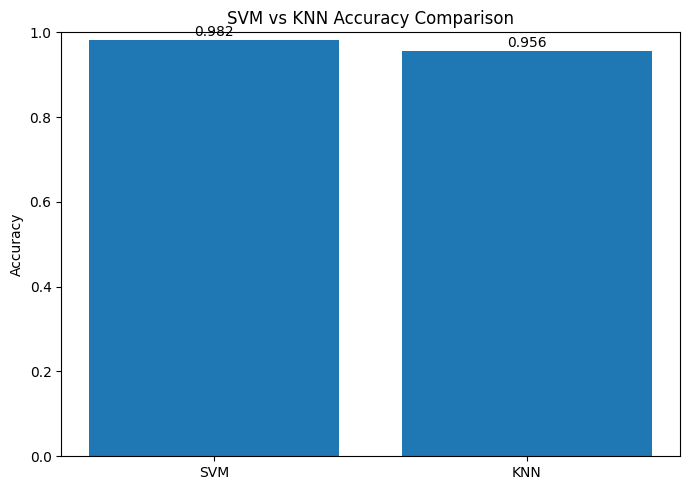

In [4]:

# Task 3: Compare model accuracy visually

models = ["SVM", "KNN"]
accuracies = [svm_accuracy, knn_accuracy]

plt.figure(figsize=(7, 5))
bars = plt.bar(models, accuracies)

plt.ylim(0, 1)
plt.ylabel("Accuracy")
plt.title("SVM vs KNN Accuracy Comparison")

for bar, score in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        score + 0.01,
        f"{score:.3f}",
        ha="center"
    )

plt.tight_layout()
plt.show()


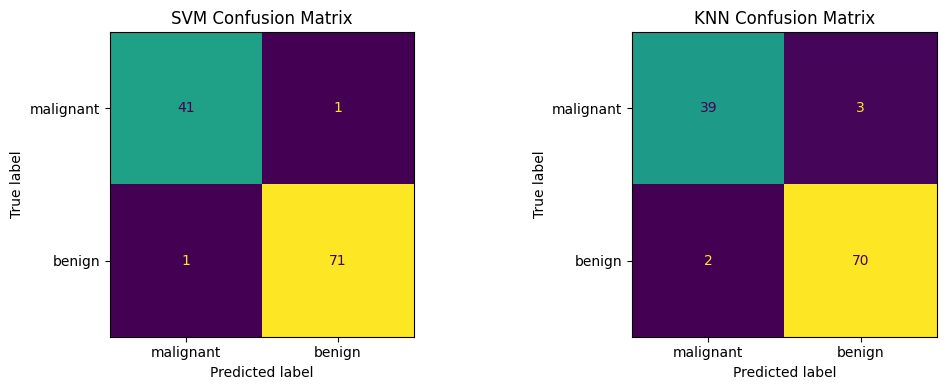

In [5]:

# Task 4: Evaluate classification errors

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ConfusionMatrixDisplay.from_predictions(
    y_test, svm_pred,
    display_labels=data.target_names,
    ax=axes[0],
    colorbar=False
)
axes[0].set_title("SVM Confusion Matrix")

ConfusionMatrixDisplay.from_predictions(
    y_test, knn_pred,
    display_labels=data.target_names,
    ax=axes[1],
    colorbar=False
)
axes[1].set_title("KNN Confusion Matrix")

plt.tight_layout()
plt.show()


In [6]:

# Task 5: Compare model performance

results = pd.DataFrame({
    "Model": ["SVM", "KNN"],
    "Accuracy": [svm_accuracy, knn_accuracy]
})

print(results.to_string(index=False))

if svm_accuracy > knn_accuracy:
    print("\nSVM performed better on this test split.")
elif knn_accuracy > svm_accuracy:
    print("\nKNN performed better on this test split.")
else:
    print("\nBoth models achieved the same accuracy.")

print("""
When to use SVM:
- Useful for high-dimensional data.
- Can model nonlinear boundaries with suitable kernels.
- Requires feature scaling and careful parameter tuning.

When to use KNN:
- Simple and intuitive.
- Useful when nearby samples tend to have similar labels.
- Prediction can be slower on large datasets.
- Sensitive to scaling, distance choice, and the value of k.
""")


Model  Accuracy
  SVM  0.982456
  KNN  0.956140

SVM performed better on this test split.

When to use SVM:
- Useful for high-dimensional data.
- Can model nonlinear boundaries with suitable kernels.
- Requires feature scaling and careful parameter tuning.

When to use KNN:
- Simple and intuitive.
- Useful when nearby samples tend to have similar labels.
- Prediction can be slower on large datasets.
- Sensitive to scaling, distance choice, and the value of k.



In [7]:

# Task 6: Basic validation tests

assert len(svm_pred) == len(y_test)
assert len(knn_pred) == len(y_test)

assert set(svm_pred).issubset({0, 1})
assert set(knn_pred).issubset({0, 1})

assert 0 <= svm_accuracy <= 1
assert 0 <= knn_accuracy <= 1

print("All validation tests passed!")


All validation tests passed!
